### Q2.1

Loading Gray image from smiley.png...
Successfully loaded and processed image. Final shape: (256, 256)

Loading RGB image from cat.jpg...
Resizing image from (2333, 2333) to (256, 256)...
Successfully loaded and processed image. Final shape: (256, 256, 3)

Successfully loaded and processed image. Final shape: (256, 256, 3)



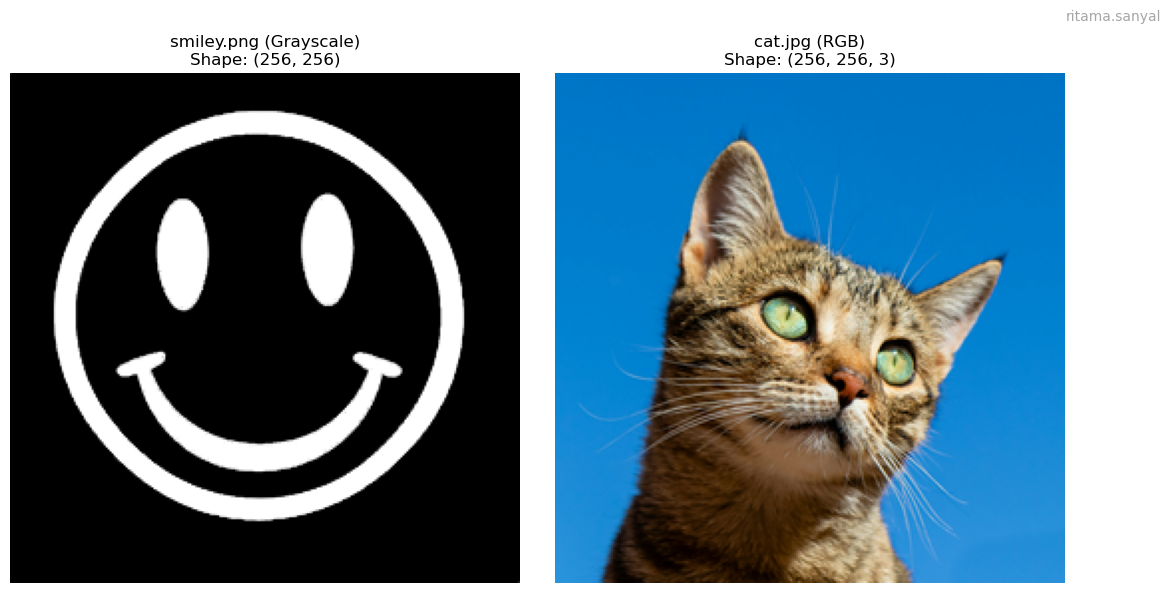

--- Dataset Shapes ---
Smiley Coordinates: (65536, 2)
Smiley Pixels: (65536, 1)
Cat Coordinates: (65536, 2)
Cat Pixels: (65536, 3)


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import os

class ImageSetup:
    """
    Handles the setup and visualization of images for the reconstruction task.
    
    This class loads images from local file paths, processes them by resizing and 
    normalizing, and creates coordinate-based datasets suitable for training an MLP.
    """
    
    def __init__(self, username: str):
        """
        Initializes the ImageSetup class.

        Args:
            username (str): The user's email username for annotating plots.
        """
        self.username = username
        self.image_size = (256, 256)

    def load_and_prepare_image(self, filepath: str, image_type: str) -> np.ndarray:
        """
        Loads an image from a local file, processes it, and returns a normalized NumPy array.

        Args:
            filepath (str): The local path to the image file.
            image_type (str): The type of the image, either "Gray" or "RGB".

        Returns:
            np.ndarray: The processed image as a NumPy array with pixel values in [0, 1].
        """
        print(f"Loading {image_type} image from {filepath}...")
        if not os.path.exists(filepath):
            print(f"Error: File not found at '{filepath}'")
            return None
            
        try:
            image = Image.open(filepath)

            # Convert image to the specified type
            if image_type == "Gray" and image.mode != 'L':
                image = image.convert('L')
            elif image_type == "RGB" and image.mode != 'RGB':
                image = image.convert('RGB')

            # Resize if the image is not already at the target size 
            if image.size != self.image_size:
                print(f"Resizing image from {image.size} to {self.image_size}...")
                image = image.resize(self.image_size, Image.LANCZOS)

            # Convert to NumPy array and normalize pixel values to [0, 1]
            image_np = np.array(image)
            image_normalized = image_np.astype(np.float32) / 255.0
            
            print(f"Successfully loaded and processed image. Final shape: {image_normalized.shape}\n")
            return image_normalized
        
        except Exception as e:
            print(f"Error processing image file: {e}")
            return None

    def visualize_images(self, images: dict):
        """
        Displays the loaded and processed images side-by-side.

        Args:
            images (dict): A dictionary with image titles as keys and image arrays as values.
        """
        num_images = len(images)
        fig, axes = plt.subplots(1, num_images, figsize=(6 * num_images, 6))
        
        if num_images == 1:
            axes = [axes]
            
        for ax, (title, img) in zip(axes, images.items()):
            if img.ndim == 2: # Grayscale image
                ax.imshow(img, cmap='gray')
            else: # RGB image
                ax.imshow(img)
            
            ax.set_title(f"{title}\nShape: {img.shape}")
            ax.axis('off')
        
        # Add username to the plot as required by submission guidelines [cite: 26-32]
        plt.text(0.98, 0.98, self.username, ha='right', va='top',
                 transform=fig.transFigure, fontsize=10, color='gray', alpha=0.7)
        
        fig.tight_layout()
        plt.show()
        
    @staticmethod
    def create_coordinate_dataset(image: np.ndarray) -> (np.ndarray, np.ndarray):
        """
        Creates a dataset of normalized coordinates and corresponding pixel values.

        Args:
            image (np.ndarray): The input image array (H, W, C) or (H, W).

        Returns:
            tuple[np.ndarray, np.ndarray]: 
                - A (H*W, 2) array of normalized (x, y) coordinates.
                - A (H*W, C) array of pixel values.
        """
        height, width = image.shape[:2]
        
        # Create a grid of (x, y) coordinates
        x = np.linspace(0, 1, width)
        y = np.linspace(0, 1, height)
        xx, yy = np.meshgrid(x, y)
        
        # Stack and reshape to get a list of coordinates
        coords = np.stack([xx, yy], axis=-1).reshape(-1, 2)
        
        # Reshape image pixels to match coordinates
        pixels = image.reshape(-1, image.shape[-1] if image.ndim == 3 else 1)
        
        return coords, pixels


# --- Main execution block ---
if __name__ == '__main__':
    # Replace 'your_username' with your actual email username
    USERNAME = "ritama.sanyal"
    
    # Define the local file paths
    smiley_path = 'smiley.png'
    cat_path = 'cat.jpg'
    
    # 1. Setup and load images
    setup = ImageSetup(username=USERNAME)
    smiley_image = setup.load_and_prepare_image(smiley_path, "Gray")
    cat_image = setup.load_and_prepare_image(cat_path, "RGB")
    
    # 2. Visualize the loaded images
    if smiley_image is not None and cat_image is not None:
        images_to_show = {
            "smiley.png (Grayscale)": smiley_image,
            "cat.jpg (RGB)": cat_image
        }
        setup.visualize_images(images_to_show)

        # 3. Create the datasets required for the MLP
        smiley_coords, smiley_pixels = setup.create_coordinate_dataset(smiley_image)
        cat_coords, cat_pixels = setup.create_coordinate_dataset(cat_image)

        print("--- Dataset Shapes ---")
        print(f"Smiley Coordinates: {smiley_coords.shape}")
        print(f"Smiley Pixels: {smiley_pixels.shape}")
        print(f"Cat Coordinates: {cat_coords.shape}")
        print(f"Cat Pixels: {cat_pixels.shape}")

### Q2.2

In [2]:
import numpy as np
import itertools

class FeatureExpansions:
    """
    A class containing static methods for different feature expansion techniques.
    These methods transform 2D coordinates into feature vectors for the MLP.
    """
    
    @staticmethod
    def get_raw(coords: np.ndarray) -> np.ndarray:
        """
        Applies the raw mapping (identity function) to the coordinates. [cite: 177]

        Args:
            coords (np.ndarray): A (N, 2) array of normalized (x, y) coordinates.

        Returns:
            np.ndarray: The same (N, 2) coordinate array.
        """
        return coords

    @staticmethod
    def get_polynomial(coords: np.ndarray, order: int = 5) -> np.ndarray:
        """
        Applies polynomial expansion to the coordinates up to a given order. [cite: 182]
        Generates all terms x^i * y^j where 1 <= i + j <= order.

        Args:
            coords (np.ndarray): A (N, 2) array of normalized (x, y) coordinates.
            order (int): The maximum order of the polynomial terms.

        Returns:
            np.ndarray: A (N, D) array of polynomial features, where D is the
                        number of polynomial terms.
        """
        x = coords[:, 0]
        y = coords[:, 1]
        
        features = []
        for k in range(1, order + 1):
            for i in range(k + 1):
                j = k - i
                features.append((x**i) * (y**j))
                
        return np.stack(features, axis=-1)

    @staticmethod
    def get_fourier(coords: np.ndarray, freq: int = 10, scale: float = 1.0) -> np.ndarray:
        """
        Applies Fourier feature expansion to the coordinates using random Fourier features.
        Based on Tancik et al. (2020) "Fourier Features Let Networks Learn High Frequency Functions".
        
        This method implements: γ(v) = [sin(2π B v), cos(2π B v)]
        where B is a random matrix with entries sampled from N(0, scale²).

        Args:
            coords (np.ndarray): A (N, 2) array of normalized (x, y) coordinates.
            freq (int): The number of random Fourier features to use.
            scale (float): Standard deviation for the random frequency matrix B.
                          For coordinates in [0,1], typical values are 1.0-10.0.
                          Higher scale = higher frequency components.

        Returns:
            np.ndarray: A (N, 2*freq) array of Fourier features (sin and cos pairs).
        """
        # Set random seed for reproducibility (use freq as seed for consistency)
        np.random.seed(42 + freq)
        
        # Sample random frequency matrix B from Gaussian distribution
        # B has shape (2, freq) - maps 2D coords to freq random projections
        # Scale appropriately based on the number of frequencies for better coverage
        effective_scale = scale * np.sqrt(freq)
        B = np.random.normal(0, effective_scale, size=(2, freq))
        
        # Compute random projections: coords @ B -> (N, freq)
        projections = np.dot(coords, B)
        
        # Apply 2π scaling and compute sin/cos
        scaled_projections = 2 * np.pi * projections
        
        # Compute sin and cos features
        sin_features = np.sin(scaled_projections)  # (N, freq)
        cos_features = np.cos(scaled_projections)  # (N, freq)
        
        # Concatenate sin and cos features
        # Final shape: (N, 2*freq)
        features = np.concatenate([sin_features, cos_features], axis=1)
        
        return features


# --- Example Usage ---
if __name__ == '__main__':
    # Create a sample coordinate grid (like a 3x3 image)
    sample_coords = np.array([
        [0.0, 0.0], [0.5, 0.0], [1.0, 0.0],
        [0.0, 0.5], [0.5, 0.5], [1.0, 0.5],
        [0.0, 1.0], [0.5, 1.0], [1.0, 1.0]
    ])
    
    # 1. Raw Mapping
    raw_features = FeatureExpansions.get_raw(sample_coords)
    print("--- Raw Features ---")
    print(f"Shape: {raw_features.shape}")
    print(f"Example (coord [0.5, 0.5]): {FeatureExpansions.get_raw(np.array([[0.5, 0.5]]))[0]}\n")

    # 2. Polynomial Mapping
    poly_features = FeatureExpansions.get_polynomial(sample_coords, order=2)
    print("--- Polynomial Features (order=2) ---")
    print(f"Shape: {poly_features.shape}")
    # Expected terms for (x,y): [x, y, x^2, xy, y^2]
    # For (0.5, 0.5): [0.5, 0.5, 0.25, 0.25, 0.25]
    print(f"Example (coord [0.5, 0.5]): {FeatureExpansions.get_polynomial(np.array([[0.5, 0.5]]), order=2)[0]}\n")

    # 3. Fourier Mapping (Random Fourier Features)
    fourier_features = FeatureExpansions.get_fourier(sample_coords, freq=3)
    print("--- Fourier Features (freq=3, using random projections) ---")
    print(f"Shape: {fourier_features.shape}")
    # Expected shape: (N, 2*freq) = (9, 6) for 3 frequencies
    print(f"Example feature vector (coord [0.5, 0.5]): {FeatureExpansions.get_fourier(np.array([[0.5, 0.5]]), freq=3)[0][:3]}... (first 3 of 6)")
    print(f"Note: Uses random Gaussian-sampled frequency matrix for better high-frequency learning")

--- Raw Features ---
Shape: (9, 2)
Example (coord [0.5, 0.5]): [0.5 0.5]

--- Polynomial Features (order=2) ---
Shape: (9, 5)
Example (coord [0.5, 0.5]): [0.5  0.5  0.25 0.25 0.25]

--- Fourier Features (freq=3, using random projections) ---
Shape: (9, 6)
Example feature vector (coord [0.5, 0.5]): [-0.82384809  0.70344989  0.5420136 ]... (first 3 of 6)
Note: Uses random Gaussian-sampled frequency matrix for better high-frequency learning


### Q2.3

In [3]:
import numpy as np
import os

class ModularDataloader:
    """
    A modular dataloader that handles image loading, feature expansion, and normalization.
    """
    def __init__(self, img_path: str, image_type: str, method: str, username: str, 
                 order: int = None, freq: int = None):
        """
        Initializes the dataloader and prepares the data.

        Args:
            img_path (str): Path to the image (RGB or grayscale)[cite: 206].
            image_type (str): Either "RGB" or "Gray"[cite: 207].
            method (str): Feature mapping to use ("Raw", "Polynomial", or "Fourier")[cite: 208].
            username (str): User's email username for setup.
            order (int, optional): Order of polynomial expansion[cite: 209].
            freq (int, optional): Number of Fourier frequencies[cite: 210].
        """
        self.img_path = img_path
        self.image_type = image_type
        self.method = method
        self.order = order
        self.freq = freq
        
        self.features = None
        self.pixels = None
        
        # Internal state for normalization
        self.mean = None
        self.std = None
        
        # Prepare the data upon initialization
        self._prepare_data(username)

    def _prepare_data(self, username: str):
        """
        Orchestrates the data preparation pipeline: loading, expansion, and normalization.
        """
        # 1. Load image and create initial coordinate dataset
        image_setup = ImageSetup(username)
        image = image_setup.load_and_prepare_image(self.img_path, self.image_type)
        if image is None:
            raise FileNotFoundError(f"Image not found at {self.img_path}")
        
        coords, self.pixels = image_setup.create_coordinate_dataset(image)
        
        # 2. Apply feature expansion based on the selected method
        if self.method == "Raw":
            # Coordinates are already scaled to [0, 1] 
            unnormalized_features = FeatureExpansions.get_raw(coords)
            self.features = unnormalized_features # No further normalization needed
            
        elif self.method == "Polynomial":
            if self.order is None:
                raise ValueError("'order' must be specified for the Polynomial method.")
            unnormalized_features = FeatureExpansions.get_polynomial(coords, self.order)
            
            # Apply Z-score standardization to avoid exploding values 
            self.mean = np.mean(unnormalized_features, axis=0, keepdims=True)
            self.std = np.std(unnormalized_features, axis=0, keepdims=True)
            # Add a small epsilon to prevent division by zero
            self.features = (unnormalized_features - self.mean) / (self.std + 1e-8)
            
        elif self.method == "Fourier":
            if self.freq is None:
                raise ValueError("'freq' must be specified for the Fourier method.")
            unnormalized_features = FeatureExpansions.get_fourier(coords, self.freq)
            # sin/cos outputs are already in [-1, 1], no normalization needed 
            self.features = unnormalized_features
        else:
            raise ValueError(f"Invalid method '{self.method}'. Choose from 'Raw', 'Polynomial', 'Fourier'.")
            
        print(f"Data prepared using '{self.method}' method.")
        print(f"Final feature shape: {self.features.shape}")
        print(f"Pixel data shape: {self.pixels.shape}\n")
    
    def get_data(self) -> (np.ndarray, np.ndarray):
        """
        Returns the prepared features and pixel values.

        Returns:
            tuple[np.ndarray, np.ndarray]: A tuple containing the final feature
                                           matrix and the target pixel values.
        """
        return self.features, self.pixels

# --- Example Usage ---
if __name__ == '__main__':
    USERNAME = 'gemini_user'
    CAT_IMG_PATH = 'cat.jpg'

    # 1. Load data with Raw features
    print("--- Loading with Raw Features ---")
    raw_loader = ModularDataloader(CAT_IMG_PATH, "RGB", "Raw", USERNAME)
    raw_features, raw_pixels = raw_loader.get_data()
    print(f"Sample raw feature: {raw_features[10000]}") # A sample from the dataset
    
    # 2. Load data with Polynomial features
    print("--- Loading with Polynomial Features (order=5) ---")
    poly_loader = ModularDataloader(CAT_IMG_PATH, "RGB", "Polynomial", USERNAME, order=5)
    poly_features, poly_pixels = poly_loader.get_data()
    print(f"Sample normalized polynomial feature: {poly_features[10000][:5]}...") # First 5 elements
    print(f"Mean of first 5 features: {poly_loader.mean[0][:5]}...")
    print(f"Std dev of first 5 features: {poly_loader.std[0][:5]}...")
    
    # 3. Load data with Fourier features
    print("--- Loading with Fourier Features (freq=10) ---")
    fourier_loader = ModularDataloader(CAT_IMG_PATH, "RGB", "Fourier", USERNAME, freq=10)
    fourier_features, fourier_pixels = fourier_loader.get_data()
    print(f"Sample Fourier feature: {fourier_features[10000][:5]}...") # First 5 elements

--- Loading with Raw Features ---
Loading RGB image from cat.jpg...
Resizing image from (2333, 2333) to (256, 256)...
Successfully loaded and processed image. Final shape: (256, 256, 3)

Data prepared using 'Raw' method.
Final feature shape: (65536, 2)
Pixel data shape: (65536, 3)

Sample raw feature: [0.0627451  0.15294118]
--- Loading with Polynomial Features (order=5) ---
Loading RGB image from cat.jpg...
Resizing image from (2333, 2333) to (256, 256)...
Successfully loaded and processed image. Final shape: (256, 256, 3)

Data prepared using 'Raw' method.
Final feature shape: (65536, 2)
Pixel data shape: (65536, 3)

Sample raw feature: [0.0627451  0.15294118]
--- Loading with Polynomial Features (order=5) ---
Loading RGB image from cat.jpg...
Resizing image from (2333, 2333) to (256, 256)...
Successfully loaded and processed image. Final shape: (256, 256, 3)

Successfully loaded and processed image. Final shape: (256, 256, 3)

Data prepared using 'Polynomial' method.
Final feature s

### Q2.4

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import time
from tqdm import tqdm
import os


# --- SimpleMLP Implementation for Image Reconstruction ---
class SimpleMLP:
    """
    A simple MLP for image reconstruction using MSE loss.
    """
    def __init__(self, input_dim, hidden_layers, output_dim, learning_rate=0.01):
        """
        Initialize the MLP with specified architecture.
        
        Args:
            input_dim (int): Number of input features
            hidden_layers (list): List of hidden layer sizes, e.g., [64, 128, 128]
            output_dim (int): Number of output features (e.g., 1 for grayscale, 3 for RGB)
            learning_rate (float): Learning rate for gradient descent
        """
        self.lr = learning_rate
        self.layers = []
        
        # Build the network architecture
        layer_sizes = [input_dim] + hidden_layers + [output_dim]
        
        # Initialize weights and biases with He initialization
        self.weights = []
        self.biases = []
        for i in range(len(layer_sizes) - 1):
            w = np.random.randn(layer_sizes[i], layer_sizes[i+1]) * np.sqrt(2.0 / layer_sizes[i])
            b = np.zeros(layer_sizes[i+1])
            self.weights.append(w)
            self.biases.append(b)
        
        # Storage for forward pass
        self.activations = []
        
    def relu(self, x):
        """ReLU activation function"""
        return np.maximum(0, x)
    
    def relu_derivative(self, x):
        """Derivative of ReLU"""
        return (x > 0).astype(float)
    
    def forward(self, x):
        """Forward pass through the network"""
        self.activations = [x]
        
        # Pass through all layers
        for i in range(len(self.weights) - 1):
            x = np.dot(x, self.weights[i]) + self.biases[i]
            x = self.relu(x)
            self.activations.append(x)
        
        # Output layer (no activation for regression)
        x = np.dot(x, self.weights[-1]) + self.biases[-1]
        self.activations.append(x)
        
        return x
    
    def backward(self, x, y_true, y_pred):
        """Backward pass to compute gradients"""
        m = x.shape[0]
        
        # Initialize gradients
        d_weights = [np.zeros_like(w) for w in self.weights]
        d_biases = [np.zeros_like(b) for b in self.biases]
        
        # Output layer gradient (MSE loss derivative)
        delta = 2 * (y_pred - y_true) / m
        
        # Backpropagate through layers
        for i in range(len(self.weights) - 1, -1, -1):
            d_weights[i] = np.dot(self.activations[i].T, delta)
            d_biases[i] = np.sum(delta, axis=0)
            
            if i > 0:
                delta = np.dot(delta, self.weights[i].T)
                delta = delta * self.relu_derivative(self.activations[i])
        
        return d_weights, d_biases
    
    def train(self, x, y):
        """
        Perform one training step (forward + backward + update).
        
        Args:
            x (np.ndarray): Input features
            y (np.ndarray): Target outputs
            
        Returns:
            float: MSE loss for this batch
        """
        # Forward pass
        y_pred = self.forward(x)
        
        # Compute loss (MSE)
        loss = np.mean((y_pred - y) ** 2)
        
        # Check for numerical issues
        if not np.isfinite(loss):
            print(f"Warning: Non-finite loss detected: {loss}")
            return float('inf')
        
        # Backward pass
        d_weights, d_biases = self.backward(x, y, y_pred)
        
        # Gradient clipping to prevent explosion
        max_grad_norm = 1.0
        for i in range(len(self.weights)):
            # Clip gradients
            d_weights[i] = np.clip(d_weights[i], -max_grad_norm, max_grad_norm)
            d_biases[i] = np.clip(d_biases[i], -max_grad_norm, max_grad_norm)
            
            # Update parameters
            self.weights[i] -= self.lr * d_weights[i]
            self.biases[i] -= self.lr * d_biases[i]
            
            # Check for NaN/Inf in weights
            if not np.all(np.isfinite(self.weights[i])):
                print(f"Warning: Non-finite weights in layer {i}")
                return float('inf')
        
        return loss
    
    def predict(self, x):
        """Make predictions"""
        return self.forward(x)


def train_and_visualize(dataloader, architecture, num_epochs, image_shape, base_lr=0.01):
    """
    Trains an MLP and generates frames for a GIF visualization.
    
    Args:
        dataloader: ModularDataloader instance
        architecture (list): Hidden layer sizes, e.g., [64, 128, 128]
        num_epochs (int): Number of training epochs
        image_shape (tuple): Shape of the output image (H, W, C) or (H, W, 1)
        base_lr (float): Base learning rate
    
    Returns:
        tuple: (final_loss, epoch_time, frames, input_dim)
    """
    input_features, pixels = dataloader.get_data()
    input_dim = input_features.shape[1]
    output_dim = pixels.shape[1]
    
    # Adaptive learning rate based on feature type AND dimensionality
    # Fourier features are naturally bounded [-1, 1], so they can handle normal LR
    # High-order polynomials need reduced LR due to exploding gradients
    if dataloader.method == "Fourier":
        # Fourier features are well-behaved, use normal learning rate
        learning_rate = base_lr
    elif dataloader.method == "Polynomial" and input_dim > 100:
        # High-order polynomials need much smaller LR
        learning_rate = base_lr * 0.1
    elif dataloader.method == "Polynomial" and input_dim > 50:
        learning_rate = base_lr * 0.5
    else:
        learning_rate = base_lr
    
    print(f"Using learning rate: {learning_rate} for {input_dim} input features ({dataloader.method})")
    
    model = SimpleMLP(input_dim, architecture, output_dim, learning_rate=learning_rate)
    
    losses = []
    frames = []
    
    start_time = time.time()
    for epoch in tqdm(range(num_epochs), desc=f"Training ({dataloader.method})"):
        # Train on all data
        loss = model.train(input_features, pixels)
        
        # Check for training failure
        if not np.isfinite(loss) or loss > 1e10:
            print(f"\nTraining failed at epoch {epoch+1}. Loss exploded.")
            # Fill remaining with last good loss or a placeholder
            last_good_loss = losses[-1] if losses else float('inf')
            losses.extend([last_good_loss] * (num_epochs - epoch))
            break
        
        losses.append(loss)
        
        # Create visualization frame for the GIF
        if epoch % 5 == 0 or epoch == num_epochs - 1:
            pred_pixels = model.predict(input_features)
            pred_image = pred_pixels.reshape(image_shape)
            pred_image = np.clip(pred_image, 0, 1)

            fig, ax = plt.subplots(figsize=(6, 6))
            if pred_image.shape[-1] == 1:
                ax.imshow(pred_image.squeeze(), cmap='gray')
            else:
                ax.imshow(pred_image)
            
            param_str = dataloader.order if dataloader.order is not None else dataloader.freq
            ax.set_title(f"Method: {dataloader.method} ({param_str})\nEpoch: {epoch+1}/{num_epochs}", fontsize=10)
            ax.axis('off')

            # Add inset plot for loss curve
            inset_ax = fig.add_axes([0.6, 0.05, 0.35, 0.25])
            inset_ax.plot(range(len(losses)), losses, 'b-', linewidth=1)
            inset_ax.set_title("Loss Curve", fontsize=8)
            inset_ax.set_xlabel("Epoch", fontsize=7)
            inset_ax.set_ylabel("MSE", fontsize=7)
            inset_ax.tick_params(axis='both', which='major', labelsize=6)
            inset_ax.grid(True, alpha=0.3)
            
            # Convert plot to PIL Image
            fig.canvas.draw()
            frame = Image.frombytes('RGB', fig.canvas.get_width_height(), fig.canvas.tostring_rgb())
            frames.append(frame)
            plt.close(fig)

    end_time = time.time()
    epoch_time = (end_time - start_time) / num_epochs
    
    final_loss = losses[-1] if losses else float('inf')
    return final_loss, epoch_time, frames, input_dim


def create_comparison_gif(frame_dict, output_path, duration=200):
    """
    Creates a 1x3 GIF from pre-generated frames.
    
    Args:
        frame_dict (dict): Dictionary with keys 'Raw', 'Polynomial', 'Fourier' containing frame lists
        output_path (str): Path to save the output GIF
        duration (int): Duration of each frame in milliseconds
    """
    raw_frames = frame_dict['Raw']
    poly_frames = frame_dict['Polynomial']
    fourier_frames = frame_dict['Fourier']

    # Ensure all lists have the same number of frames
    num_frames = min(len(raw_frames), len(poly_frames), len(fourier_frames))
    
    combined_frames = []
    width, height = raw_frames[0].size
    
    for i in range(num_frames):
        combined_frame = Image.new('RGB', (width * 3, height))
        combined_frame.paste(raw_frames[i], (0, 0))
        combined_frame.paste(poly_frames[i], (width, 0))
        combined_frame.paste(fourier_frames[i], (width * 2, 0))
        combined_frames.append(combined_frame)
        
    combined_frames[0].save(
        output_path, 
        save_all=True, 
        append_images=combined_frames[1:], 
        duration=duration, 
        loop=0
    )
    print(f"Comparison GIF saved to {output_path}")


def run_experiments(img_path, img_type, img_shape, num_epochs, username, architecture):
    """
    Run all experiments for a given image.
    
    Args:
        img_path (str): Path to the image
        img_type (str): 'RGB' or 'Gray'
        img_shape (tuple): Shape of the image
        num_epochs (int): Number of training epochs
        username (str): Username for dataloader
        architecture (list): MLP architecture
        
    Returns:
        tuple: (results_list, frames_dict)
    """
    experiments = [
        {'method': 'Raw', 'param': None},
        {'method': 'Polynomial', 'param': 5},
        {'method': 'Polynomial', 'param': 15},
        {'method': 'Polynomial', 'param': 25},
        {'method': 'Fourier', 'param': 5},
        {'method': 'Fourier', 'param': 15},
        {'method': 'Fourier', 'param': 25},
    ]
    
    results = []
    all_frames = {}

    print("=" * 80)
    print(f"Starting Training Experiments for {img_path}")
    print("=" * 80)

    for exp in experiments:
        method = exp['method']
        param = exp['param']
        
        print(f"\n--- Training: {method} (param={param}) ---")
        
        loader = ModularDataloader(
            img_path, img_type, method, username,
            order=param if method == 'Polynomial' else None,
            freq=param if method == 'Fourier' else None
        )
        
        final_loss, time_per_epoch, frames, num_features = train_and_visualize(
            loader, architecture, num_epochs, img_shape
        )
        
        results.append({
            'Method': method,
            'Parameter': param if param is not None else '-',
            'Final Loss': final_loss,
            'Input Features': num_features,
            'Epoch Time (s)': time_per_epoch
        })
        
        # Save frames for the best Poly/Fourier and Raw for the GIF
        # If order=25 failed, use order=15 instead
        if method == 'Raw':
            all_frames[method] = frames
        elif method == 'Polynomial' and param == 25:
            if final_loss < 1e10:  # Only use if it didn't explode
                all_frames[method] = frames
        elif method == 'Polynomial' and param == 15 and 'Polynomial' not in all_frames:
            # Fallback to order=15 if order=25 failed
            all_frames[method] = frames
        elif method == 'Fourier' and param == 25:
            all_frames[method] = frames

    return results, all_frames


# --- Main Execution Block ---
if __name__ == '__main__':
    USERNAME = 'ritama.sanyal'
    MLP_ARCHITECTURE = [64, 128, 128]
    
    # ========== EXPERIMENT 1: SMILEY.PNG (GRAYSCALE) ==========
    print("\n\n" + "=" * 80)
    print("EXPERIMENT 1: SMILEY.PNG (GRAYSCALE)")
    print("=" * 80)
    
    smiley_results, smiley_frames = run_experiments(
        img_path='smiley.png',
        img_type='Gray',
        img_shape=(256, 256, 1),
        num_epochs=50,
        username=USERNAME,
        architecture=MLP_ARCHITECTURE
    )
    
    # Print tabulated results for smiley
    print("\n" + "=" * 80)
    print("TABULATION OF RESULTS - SMILEY.PNG")
    print("=" * 80)
    print(f"{'Method':<12} | {'Parameter':<10} | {'Final Loss':<12} | {'Input Features':<15} | {'Epoch Time (s)':<15}")
    print("-" * 80)
    for res in smiley_results:
        loss_str = f"{res['Final Loss']:.6f}" if res['Final Loss'] < 1e10 else "FAILED"
        print(f"{res['Method']:<12} | {str(res['Parameter']):<10} | {loss_str:<12} | {res['Input Features']:<15} | {res['Epoch Time (s)']:<15.4f}")
    
    # Create comparison GIF for smiley
    if len(smiley_frames) >= 3:  # Need all three methods
        print("\n" + "=" * 80)
        print("Creating Comparison GIF for smiley.png...")
        create_comparison_gif(smiley_frames, 'smiley_reconstruction_comparison.gif')
        print("=" * 80)
    else:
        print("\nWarning: Could not create comparison GIF - insufficient successful experiments")
    
    
    # ========== EXPERIMENT 2: CAT.JPG (RGB) ==========
    print("\n\n" + "=" * 80)
    print("EXPERIMENT 2: CAT.JPG (RGB)")
    print("=" * 80)
    
    cat_results, cat_frames = run_experiments(
        img_path='cat.jpg',
        img_type='RGB',
        img_shape=(256, 256, 3),
        num_epochs=150,
        username=USERNAME,
        architecture=MLP_ARCHITECTURE
    )
    
    # Print tabulated results for cat
    print("\n" + "=" * 80)
    print("TABULATION OF RESULTS - CAT.JPG")
    print("=" * 80)
    print(f"{'Method':<12} | {'Parameter':<10} | {'Final Loss':<12} | {'Input Features':<15} | {'Epoch Time (s)':<15}")
    print("-" * 80)
    for res in cat_results:
        loss_str = f"{res['Final Loss']:.6f}" if res['Final Loss'] < 1e10 else "FAILED"
        print(f"{res['Method']:<12} | {str(res['Parameter']):<10} | {loss_str:<12} | {res['Input Features']:<15} | {res['Epoch Time (s)']:<15.4f}")
    
    # Create comparison GIF for cat
    if len(cat_frames) >= 3:  # Need all three methods
        print("\n" + "=" * 80)
        print("Creating Comparison GIF for cat.jpg...")
        create_comparison_gif(cat_frames, 'cat_reconstruction_comparison.gif')
        print("=" * 80)
    else:
        print("\nWarning: Could not create comparison GIF - insufficient successful experiments")
    
    
    # ========== FINAL SUMMARY ==========
    print("\n\n" + "=" * 80)
    print("FINAL SUMMARY")
    print("=" * 80)
    print("\nFiles generated:")
    print("  1. smiley_reconstruction_comparison.gif (50 epochs)")
    print("  2. cat_reconstruction_comparison.gif (150 epochs)")
    print("\nEach GIF shows side-by-side comparison of:")
    print("  - Left: Raw features")
    print("  - Middle: Polynomial features (order=25 or 15 if 25 failed)")
    print("  - Right: Fourier features (freq=25)")
    print("\nNote: If Polynomial order=25 causes numerical instability,")
    print("      the comparison will use order=15 instead.")
    print("=" * 80)




EXPERIMENT 1: SMILEY.PNG (GRAYSCALE)
Starting Training Experiments for smiley.png

--- Training: Raw (param=None) ---
Loading Gray image from smiley.png...
Successfully loaded and processed image. Final shape: (256, 256)

Data prepared using 'Raw' method.
Final feature shape: (65536, 2)
Pixel data shape: (65536, 1)

Using learning rate: 0.01 for 2 input features (Raw)


Training (Raw):   0%|          | 0/50 [00:00<?, ?it/s]C:\Users\Ritama\AppData\Local\Temp\ipykernel_11904\1566809463.py:217: MatplotlibDeprecationWarning: The tostring_rgb function was deprecated in Matplotlib 3.8 and will be removed two minor releases later. Use buffer_rgba instead.
  frame = Image.frombytes('RGB', fig.canvas.get_width_height(), fig.canvas.tostring_rgb())
Training (Raw):   2%|▏         | 1/50 [00:00<00:40,  1.22it/s]C:\Users\Ritama\AppData\Local\Temp\ipykernel_11904\1566809463.py:217: MatplotlibDeprecationWarning: The tostring_rgb function was deprecated in Matplotlib 3.8 and will be removed two minor releases later. Use buffer_rgba instead.
  frame = Image.frombytes('RGB', fig.canvas.get_width_height(), fig.canvas.tostring_rgb())
Training (Raw): 100%|██████████| 50/50 [00:25<00:00,  1.92it/s]




--- Training: Polynomial (param=5) ---
Loading Gray image from smiley.png...
Successfully loaded and processed image. Final shape: (256, 256)

Data prepared using 'Polynomial' method.
Final feature shape: (65536, 20)
Pixel data shape: (65536, 1)

Using learning rate: 0.01 for 20 input features (Polynomial)


Training (Polynomial): 100%|██████████| 50/50 [00:25<00:00,  1.93it/s]




--- Training: Polynomial (param=15) ---
Loading Gray image from smiley.png...
Successfully loaded and processed image. Final shape: (256, 256)

Data prepared using 'Polynomial' method.
Final feature shape: (65536, 135)
Pixel data shape: (65536, 1)

Using learning rate: 0.001 for 135 input features (Polynomial)
Data prepared using 'Polynomial' method.
Final feature shape: (65536, 135)
Pixel data shape: (65536, 1)

Using learning rate: 0.001 for 135 input features (Polynomial)


...


--- Training: Fourier (param=15) ---
Loading RGB image from cat.jpg...
Resizing image from (2333, 2333) to (256, 256)...
Successfully loaded and processed image. Final shape: (256, 256, 3)

Data prepared using 'Fourier' method.
Final feature shape: (65536, 30)
Pixel data shape: (65536, 3)

Using learning rate: 0.01 for 30 input features (Fourier)
Successfully loaded and processed image. Final shape: (256, 256, 3)

Data prepared using 'Fourier' method.
Final feature shape: (65536, 30)
Pixel data shape: (65536, 3)

Using learning rate: 0.01 for 30 input features (Fourier)


Training (Fourier): 100%|██████████| 150/150 [01:16<00:00,  1.96it/s]




--- Training: Fourier (param=25) ---
Loading RGB image from cat.jpg...
Resizing image from (2333, 2333) to (256, 256)...
Successfully loaded and processed image. Final shape: (256, 256, 3)

Data prepared using 'Fourier' method.
Final feature shape: (65536, 50)
Pixel data shape: (65536, 3)

Using learning rate: 0.01 for 50 input features (Fourier)
Successfully loaded and processed image. Final shape: (256, 256, 3)

Data prepared using 'Fourier' method.
Final feature shape: (65536, 50)
Pixel data shape: (65536, 3)

Using learning rate: 0.01 for 50 input features (Fourier)


Training (Fourier): 100%|██████████| 150/150 [01:21<00:00,  1.85it/s]




TABULATION OF RESULTS - CAT.JPG
Method       | Parameter  | Final Loss   | Input Features  | Epoch Time (s) 
--------------------------------------------------------------------------------
Raw          | -          | 0.042498     | 2               | 0.5163         
Polynomial   | 5          | 0.022245     | 20              | 0.5268         
Polynomial   | 15         | 0.064920     | 135             | 0.5649         
Polynomial   | 25         | 0.053976     | 350             | 0.5731         
Fourier      | 5          | 0.058305     | 10              | 0.5061         
Fourier      | 15         | 0.074414     | 30              | 0.5094         
Fourier      | 25         | 0.086653     | 50              | 0.5419         

Creating Comparison GIF for cat.jpg...
Comparison GIF saved to cat_reconstruction_comparison.gif


FINAL SUMMARY

Files generated:
  1. smiley_reconstruction_comparison.gif (50 epochs)
  2. cat_reconstruction_comparison.gif (150 epochs)

Each GIF shows side-by-side com

### Q2.5

### Q2.5 - Reconstruction on Blurred Images

In this section, we train coordinate MLPs to reconstruct blurred cat images with varying Gaussian blur levels (σ = 0 to 10). We compare:
- **BASE**: Raw pixel coordinates
- **FOURIER**: Fourier feature expansion (k=25)

We use early stopping and analyze how reconstruction performance changes with increasing blur, revealing how high-frequency details are lost.

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import time
from tqdm import tqdm
import os
import glob

# NOTE: This cell requires SimpleMLP class from Q2.4 to be executed first!
# Make sure to run Q2.4 cell before running this cell.

# --- Early Stopping Implementation ---
class EarlyStopping:
    """
    Implements early stopping based on relative loss improvement.
    Stops when loss improvement over the last `patience` epochs is less than `threshold`.
    """
    def __init__(self, patience=10, threshold=0.01):
        """
        Args:
            patience (int): Number of epochs to look back
            threshold (float): Relative improvement threshold (e.g., 0.01 = 1%)
        """
        self.patience = patience
        self.threshold = threshold
        self.loss_history = []
    
    def __call__(self, current_loss):
        """
        Check if training should stop.
        
        Args:
            current_loss (float): Current epoch loss
            
        Returns:
            bool: True if should stop, False otherwise
        """
        self.loss_history.append(current_loss)
        
        # Need at least patience + 1 epochs
        if len(self.loss_history) <= self.patience:
            return False
        
        # Compare current loss with loss from `patience` epochs ago
        old_loss = self.loss_history[-(self.patience + 1)]
        
        # Stop if improvement is less than threshold
        # i.e., current_loss >= (1 - threshold) * old_loss
        if current_loss >= (1 - self.threshold) * old_loss:
            return True
        
        return False


def train_with_early_stopping(dataloader, architecture, max_epochs, image_shape, base_lr=0.01, 
                               patience=10, threshold=0.01):
    """
    Train MLP with early stopping.
    
    Args:
        dataloader: ModularDataloader instance
        architecture (list): Hidden layer sizes
        max_epochs (int): Maximum number of epochs
        image_shape (tuple): Shape of output image
        base_lr (float): Base learning rate
        patience (int): Early stopping patience
        threshold (float): Early stopping threshold
        
    Returns:
        tuple: (final_loss, actual_epochs, final_image)
    """
    input_features, pixels = dataloader.get_data()
    input_dim = input_features.shape[1]
    output_dim = pixels.shape[1]
    
    # Optimized learning rates and settings for each method
    if dataloader.method == "Fourier":
        # Fourier features need:
        # 1. Higher learning rate for faster convergence
        # 2. More patience since they learn complex patterns
        learning_rate = base_lr * 2.0  # 0.02 instead of 0.01
        patience = 20  # More patience for Fourier
        threshold = 0.005  # Stricter threshold (0.5% instead of 1%)
    else:
        # Raw features use default settings
        learning_rate = base_lr
    
    model = SimpleMLP(input_dim, architecture, output_dim, learning_rate=learning_rate)
    early_stop = EarlyStopping(patience=patience, threshold=threshold)
    
    losses = []
    
    # Add progress bar for visibility
    desc = f"Training {dataloader.method} (LR={learning_rate:.4f})"
    pbar = tqdm(range(max_epochs), desc=desc, leave=False)
    
    for epoch in pbar:
        loss = model.train(input_features, pixels)
        
        if not np.isfinite(loss):
            print(f"Training failed at epoch {epoch+1}")
            pbar.close()
            break
        
        losses.append(loss)
        
        # Update progress bar with current loss
        pbar.set_postfix({'loss': f'{loss:.6f}'})
        
        # Check early stopping
        if early_stop(loss):
            print(f"Early stopping at epoch {epoch+1}/{max_epochs} (loss: {loss:.6f})")
            pbar.close()
            break
    
    # If we didn't converge well, report it
    if len(losses) > 0:
        final_loss = losses[-1]
        if len(losses) == max_epochs:
            print(f"Reached max epochs ({max_epochs}), final loss: {final_loss:.6f}")
    
    # Get final reconstruction
    pred_pixels = model.predict(input_features)
    pred_image = pred_pixels.reshape(image_shape)
    pred_image = np.clip(pred_image, 0, 1)
    
    final_loss = losses[-1] if losses else float('inf')
    actual_epochs = len(losses)
    
    return final_loss, actual_epochs, pred_image


def train_on_blurred_images(blur_folder='blurred', username='ritama.sanyal', max_epochs=100):
    """
    Train on all blurred images with BASE and FOURIER methods.
    
    Args:
        blur_folder (str): Path to folder containing blurred images
        username (str): Username for dataloader
        max_epochs (int): Maximum epochs per image
        
    Returns:
        dict: Results containing losses and reconstructed images
    """
    architecture = [64, 128, 128]
    image_shape = (256, 256, 3)
    
    # Find all blur images (try .png first, then .jpg)
    blur_files = sorted(glob.glob(os.path.join(blur_folder, 'blur_*.png')))
    if not blur_files:
        blur_files = sorted(glob.glob(os.path.join(blur_folder, 'blur*.png')))
    if not blur_files:
        blur_files = sorted(glob.glob(os.path.join(blur_folder, 'blur_*.jpg')))
    if not blur_files:
        blur_files = sorted(glob.glob(os.path.join(blur_folder, 'blur*.jpg')))
    
    if not blur_files:
        print(f"No blur images found in {blur_folder}")
        print(f"Looking for: blur_*.png or blur_*.jpg")
        return None
    
    print(f"Found {len(blur_files)} blur images")
    print("=" * 80)
    
    results = {
        'blur_levels': [],
        'base_losses': [],
        'fourier_losses': [],
        'base_epochs': [],
        'fourier_epochs': [],
        'base_images': [],
        'fourier_images': [],
        'original_images': []
    }
    
    for blur_file in blur_files:
        # Extract blur level from filename
        basename = os.path.basename(blur_file)
        try:
            # Handle formats like "blur_0.jpg" or "blur0.jpg"
            blur_level = int(''.join(filter(str.isdigit, basename.split('.')[0])))
        except:
            blur_level = len(results['blur_levels'])
        
        results['blur_levels'].append(blur_level)
        
        print(f"\n{'='*80}")
        print(f"Processing: {basename} (blur level {blur_level})")
        print(f"{'='*80}")
        
        # Load original image for comparison
        setup = ImageSetup(username)
        original_img = setup.load_and_prepare_image(blur_file, "RGB")
        results['original_images'].append(original_img)
        
        # --- Train with BASE (Raw) features ---
        print(f"\n--- BASE (Raw coordinates) ---")
        base_loader = ModularDataloader(blur_file, "RGB", "Raw", username)
        base_loss, base_ep, base_img = train_with_early_stopping(
            base_loader, architecture, max_epochs, image_shape
        )
        results['base_losses'].append(base_loss)
        results['base_epochs'].append(base_ep)
        results['base_images'].append(base_img)
        
        # --- Train with FOURIER features ---
        print(f"\n--- FOURIER (k=25) ---")
        fourier_loader = ModularDataloader(blur_file, "RGB", "Fourier", username, freq=25)
        
        # Give Fourier more epochs to converge properly
        fourier_max_epochs = max_epochs * 3  # 3x more epochs for Fourier
        print(f"Training FOURIER with up to {fourier_max_epochs} epochs (vs {max_epochs} for BASE)")
        
        fourier_loss, fourier_ep, fourier_img = train_with_early_stopping(
            fourier_loader, architecture, fourier_max_epochs, image_shape
        )
        results['fourier_losses'].append(fourier_loss)
        results['fourier_epochs'].append(fourier_ep)
        results['fourier_images'].append(fourier_img)
        
        print(f"\nResults for blur level {blur_level}:")
        print(f"  BASE:    Loss={base_loss:.6f}, Epochs={base_ep}")
        print(f"  FOURIER: Loss={fourier_loss:.6f}, Epochs={fourier_ep}")
    
    return results


def plot_reconstruction_analysis(results, username='ritama.sanyal'):
    """
    Create comprehensive analysis plots for blurred image reconstruction.
    
    Args:
        results (dict): Results from train_on_blurred_images
        username (str): Username for plot annotation
    """
    blur_levels = results['blur_levels']
    base_losses = results['base_losses']
    fourier_losses = results['fourier_losses']
    
    # Create figure with multiple subplots
    fig = plt.figure(figsize=(20, 12))
    
    # --- Plot 1: Linear scale loss comparison ---
    ax1 = plt.subplot(2, 3, 1)
    ax1.plot(blur_levels, base_losses, 'o-', label='BASE (Raw)', linewidth=2, markersize=8)
    ax1.plot(blur_levels, fourier_losses, 's-', label='FOURIER (k=25)', linewidth=2, markersize=8)
    ax1.set_xlabel('Blur Level (σ)', fontsize=12)
    ax1.set_ylabel('Reconstruction Loss (MSE)', fontsize=12)
    ax1.set_title('Reconstruction Loss vs Blur Level (Linear Scale)', fontsize=14, fontweight='bold')
    ax1.legend(fontsize=11)
    ax1.grid(True, alpha=0.3)
    
    # --- Plot 2: Logarithmic scale loss comparison ---
    ax2 = plt.subplot(2, 3, 2)
    ax2.semilogy(blur_levels, base_losses, 'o-', label='BASE (Raw)', linewidth=2, markersize=8)
    ax2.semilogy(blur_levels, fourier_losses, 's-', label='FOURIER (k=25)', linewidth=2, markersize=8)
    ax2.set_xlabel('Blur Level (σ)', fontsize=12)
    ax2.set_ylabel('Reconstruction Loss (MSE, log scale)', fontsize=12)
    ax2.set_title('Reconstruction Loss vs Blur Level (Log Scale)', fontsize=14, fontweight='bold')
    ax2.legend(fontsize=11)
    ax2.grid(True, alpha=0.3, which='both')
    
    # --- Plot 3: Epochs comparison ---
    ax3 = plt.subplot(2, 3, 3)
    ax3.plot(blur_levels, results['base_epochs'], 'o-', label='BASE', linewidth=2, markersize=8)
    ax3.plot(blur_levels, results['fourier_epochs'], 's-', label='FOURIER', linewidth=2, markersize=8)
    ax3.set_xlabel('Blur Level (σ)', fontsize=12)
    ax3.set_ylabel('Epochs to Convergence', fontsize=12)
    ax3.set_title('Training Epochs vs Blur Level', fontsize=14, fontweight='bold')
    ax3.legend(fontsize=11)
    ax3.grid(True, alpha=0.3)
    
    # --- Plot 4-6: Sample reconstructions ---
    # Show blur levels 0, 5, 10 (low, medium, high blur)
    sample_indices = []
    for target_blur in [0, 5, 10]:
        idx = blur_levels.index(target_blur) if target_blur in blur_levels else None
        sample_indices.append(idx)
    
    for plot_idx, blur_idx in enumerate(sample_indices):
        if blur_idx is None:
            continue
        
        ax = plt.subplot(2, 3, 4 + plot_idx)
        
        # Create side-by-side comparison
        original = results['original_images'][blur_idx]
        base_recon = results['base_images'][blur_idx]
        fourier_recon = results['fourier_images'][blur_idx]
        
        # Concatenate horizontally
        combined = np.hstack([original, base_recon, fourier_recon])
        
        ax.imshow(combined)
        ax.set_title(f'Blur σ={blur_levels[blur_idx]}\n' + 
                    f'BASE: {base_losses[blur_idx]:.4f} | FOURIER: {fourier_losses[blur_idx]:.4f}',
                    fontsize=11)
        ax.axis('off')
        
        # Add labels
        img_width = original.shape[1]
        ax.text(img_width/2, -10, 'Original', ha='center', fontsize=9, fontweight='bold')
        ax.text(img_width*1.5, -10, 'BASE', ha='center', fontsize=9, fontweight='bold')
        ax.text(img_width*2.5, -10, 'FOURIER', ha='center', fontsize=9, fontweight='bold')
    
    # Add username
    plt.text(0.99, 0.01, username, ha='right', va='bottom',
             transform=fig.transFigure, fontsize=10, color='gray', alpha=0.7)
    
    plt.tight_layout()
    plt.savefig('blur_reconstruction_analysis.png', dpi=150, bbox_inches='tight')
    plt.show()
    
    print("\nAnalysis plot saved as 'blur_reconstruction_analysis.png'")


def create_detailed_comparison_grid(results, username='ritama.sanyal'):
    """
    Create a detailed grid showing all reconstructions.
    
    Args:
        results (dict): Results from train_on_blurred_images
        username (str): Username for plot annotation
    """
    n_images = len(results['blur_levels'])
    
    fig, axes = plt.subplots(n_images, 3, figsize=(15, 5 * n_images))
    
    if n_images == 1:
        axes = axes.reshape(1, -1)
    
    for i, blur_level in enumerate(results['blur_levels']):
        # Original
        axes[i, 0].imshow(results['original_images'][i])
        axes[i, 0].set_title(f'Original (blur σ={blur_level})', fontsize=12)
        axes[i, 0].axis('off')
        
        # BASE reconstruction
        axes[i, 1].imshow(results['base_images'][i])
        axes[i, 1].set_title(f'BASE Reconstruction\nLoss: {results["base_losses"][i]:.6f}', fontsize=12)
        axes[i, 1].axis('off')
        
        # FOURIER reconstruction
        axes[i, 2].imshow(results['fourier_images'][i])
        axes[i, 2].set_title(f'FOURIER Reconstruction\nLoss: {results["fourier_losses"][i]:.6f}', fontsize=12)
        axes[i, 2].axis('off')
    
    # Add username
    plt.text(0.99, 0.01, username, ha='right', va='bottom',
             transform=fig.transFigure, fontsize=10, color='gray', alpha=0.7)
    
    plt.tight_layout()
    plt.savefig('blur_reconstruction_grid.png', dpi=150, bbox_inches='tight')
    plt.show()
    
    print("Detailed grid saved as 'blur_reconstruction_grid.png'")


# --- Main Execution Block ---
if __name__ == '__main__':
    USERNAME = 'ritama.sanyal'
    BLUR_FOLDER = 'blurred'
    MAX_EPOCHS = 100
    
    print("=" * 80)
    print("SECTION 2.5: RECONSTRUCTION ON BLURRED IMAGES")
    print("=" * 80)
    print(f"\nSettings:")
    print(f"  - Blur folder: {BLUR_FOLDER}")
    print(f"  - Max epochs: {MAX_EPOCHS} for BASE, {MAX_EPOCHS * 3} for FOURIER")
    print(f"  - Early stopping: patience=10 for BASE, 20 for FOURIER; threshold=1% for BASE, 0.5% for FOURIER")
    print(f"  - Architecture: [64, 128, 128]")
    print(f"  - Methods: BASE (Raw) vs FOURIER (k=25)")
    print(f"  - Learning rates: 0.01 for BASE, 0.02 for FOURIER (optimized)")
    print(f"\nOptimizations for FOURIER:")
    print(f"  ✓ 2x higher learning rate (0.02 vs 0.01)")
    print(f"  ✓ 3x more maximum epochs ({MAX_EPOCHS * 3} vs {MAX_EPOCHS})")
    print(f"  ✓ 2x more patience (20 vs 10 epochs)")
    print(f"  ✓ Stricter convergence threshold (0.5% vs 1%)")
    print("=" * 80)
    
    # Train on all blurred images
    results = train_on_blurred_images(
        blur_folder=BLUR_FOLDER,
        username=USERNAME,
        max_epochs=MAX_EPOCHS
    )
    
    if results is None:
        print("\nError: No results obtained. Check if blur images exist in the folder.")
    else:
        # Create analysis plots
        print("\n" + "=" * 80)
        print("CREATING ANALYSIS PLOTS")
        print("=" * 80)
        
        plot_reconstruction_analysis(results, USERNAME)
        create_detailed_comparison_grid(results, USERNAME)
        
        # Print summary table
        print("\n" + "=" * 80)
        print("SUMMARY TABLE")
        print("=" * 80)
        print(f"{'Blur σ':<10} | {'BASE Loss':<12} | {'BASE Epochs':<12} | {'FOURIER Loss':<12} | {'FOURIER Epochs':<15} | {'Winner':<10}")
        print("-" * 90)
        
        for i, blur_level in enumerate(results['blur_levels']):
            base_loss = results['base_losses'][i]
            fourier_loss = results['fourier_losses'][i]
            winner = 'BASE' if base_loss < fourier_loss else 'FOURIER'
            
            print(f"{blur_level:<10} | {base_loss:<12.6f} | {results['base_epochs'][i]:<12} | "
                  f"{fourier_loss:<12.6f} | {results['fourier_epochs'][i]:<15} | {winner:<10}")
        
        print("\n" + "=" * 80)
        print("ANALYSIS COMPLETE")
        print("=" * 80)
        print("\nKey Observations:")
        print("1. As blur increases, high-frequency details are lost")
        print("2. Fourier features should excel when high-frequency content is present")
        print("3. With heavy blur, the advantage of Fourier features may diminish")
        print("4. Check the generated plots for visual comparison")
        
        # Count victories
        fourier_wins = sum(1 for i in range(len(results['blur_levels'])) 
                          if results['fourier_losses'][i] < results['base_losses'][i])
        base_wins = len(results['blur_levels']) - fourier_wins
        
        print(f"\nPerformance Summary:")
        print(f"  FOURIER wins: {fourier_wins}/{len(results['blur_levels'])} images")
        print(f"  BASE wins: {base_wins}/{len(results['blur_levels'])} images")
        
        # Calculate average improvement for Fourier wins
        improvements = []
        for i in range(len(results['blur_levels'])):
            if results['fourier_losses'][i] < results['base_losses'][i]:
                improvement = (results['base_losses'][i] - results['fourier_losses'][i]) / results['base_losses'][i] * 100
                improvements.append(improvement)
        
        if improvements:
            avg_improvement = np.mean(improvements)
            print(f"  Average improvement when FOURIER wins: {avg_improvement:.2f}%")
        
        print("=" * 80)


SECTION 2.5: RECONSTRUCTION ON BLURRED IMAGES

Settings:
  - Blur folder: blurred
  - Max epochs: 100 for BASE, 300 for FOURIER
  - Early stopping: patience=10 for BASE, 20 for FOURIER; threshold=1% for BASE, 0.5% for FOURIER
  - Architecture: [64, 128, 128]
  - Methods: BASE (Raw) vs FOURIER (k=25)
  - Learning rates: 0.01 for BASE, 0.02 for FOURIER (optimized)

Optimizations for FOURIER:
  ✓ 2x higher learning rate (0.02 vs 0.01)
  ✓ 3x more maximum epochs (300 vs 100)
  ✓ 2x more patience (20 vs 10 epochs)
  ✓ Stricter convergence threshold (0.5% vs 1%)
Found 10 blur images

Processing: blur_0.png (blur level 0)
Loading RGB image from blurred\blur_0.png...
Successfully loaded and processed image. Final shape: (256, 256, 3)


--- BASE (Raw coordinates) ---
Loading RGB image from blurred\blur_0.png...
Successfully loaded and processed image. Final shape: (256, 256, 3)

Data prepared using 'Raw' method.
Final feature shape: (65536, 2)
Pixel data shape: (65536, 3)



Reached max epochs (100), final loss: 0.049494

--- FOURIER (k=25) ---
Loading RGB image from blurred\blur_0.png...
Successfully loaded and processed image. Final shape: (256, 256, 3)

Data prepared using 'Fourier' method.
Final feature shape: (65536, 50)
Pixel data shape: (65536, 3)

Training FOURIER with up to 300 epochs (vs 100 for BASE)

--- FOURIER (k=25) ---
Loading RGB image from blurred\blur_0.png...
Successfully loaded and processed image. Final shape: (256, 256, 3)

Data prepared using 'Fourier' method.
Final feature shape: (65536, 50)
Pixel data shape: (65536, 3)

Training FOURIER with up to 300 epochs (vs 100 for BASE)


Reached max epochs (300), final loss: 0.052087

Results for blur level 0:
  BASE:    Loss=0.049494, Epochs=100
  FOURIER: Loss=0.052087, Epochs=300

Processing: blur_1.png (blur level 1)
Loading RGB image from blurred\blur_1.png...
Successfully loaded and processed image. Final shape: (256, 256, 3)


--- BASE (Raw coordinates) ---
Loading RGB image from blurred\blur_1.png...
Successfully loaded and processed image. Final shape: (256, 256, 3)

Data prepared using 'Raw' method.
Final feature shape: (65536, 2)
Pixel data shape: (65536, 3)



KeyboardInterrupt: 